# Problem 7: 


In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42

## (a) Load the data and choose k for k-fold cross-validation

In [13]:
df = pd.read_csv('SMSSpamCollection.tsv', sep='\t', names=['label', 'message'], header=None)
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [14]:
print(f"Rows: {len(df)}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

class_df = pd.DataFrame({
    "Count": df["label"].value_counts(),
    "Proportion": df["label"].value_counts(normalize=True).round(3),
})
display(class_df)

Rows: 5572
Missing values: 0
Duplicate rows: 403


,Count,Proportion
label,,
ham,4825,0.866
spam,747,0.134


### Choice of k

I use **k = 10 with stratified folds** Because with 5,572 messages, each test fold holds about 557 messages and about 75 of them are spam. That is enough minority-class examples for precision, recall, and F1 to be meaningful in every fold. It also give low bias, cheap to compute

In [15]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

fold_sizes = pd.DataFrame(
    [{"Fold": i + 1, "Test size": len(test_idx), "Spam in test": int((df["label"].iloc[test_idx] == "spam").sum())}
     for i, (_, test_idx) in enumerate(cv.split(df["message"], df["label"]))]
).set_index("Fold")
display(fold_sizes.T)

Fold,1,2,3,4,5,6,7,8,9,10
Test size,558,558,557,557,557,557,557,557,557,557
Spam in test,75,75,74,74,74,75,75,75,75,75


## (b) Encode the messages with `CountVectorizer`

In [16]:
X = df["message"]
y = (df["label"] == "spam").astype(int)

# Illustration only: fit the vectorizer on all messages to show what the encoding looks like.
demo_vectorizer = CountVectorizer()
X_counts = demo_vectorizer.fit_transform(X)
print(f"Document-term matrix shape: {X_counts.shape}  (messages x vocabulary words)")
print(f"Non-zero entries: {X_counts.nnz} ({X_counts.nnz / np.prod(X_counts.shape):.4%} of the matrix)")

example = pd.Series(X_counts[2].toarray().ravel(), index=demo_vectorizer.get_feature_names_out())
print("\nMessage:", X.iloc[2])
display(example[example > 0].to_frame("count").T)

Document-term matrix shape: (5572, 8713)  (messages x vocabulary words)
Non-zero entries: 74169 (0.1528% of the matrix)

Message: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's


,08452810075over18,2005,21st,87121,apply,comp,cup,entry,fa,final,...,question,rate,receive,std,text,tkts,to,txt,win,wkly
count,1,1,1,1,1,1,1,2,2,1,...,1,1,1,1,1,1,3,1,1,1


In [17]:
pipe = Pipeline([
    ("vect", CountVectorizer()),
    ("nb", MultinomialNB(alpha=1.0)),  # alpha=1 is Laplace smoothing, as in the lecture CPTs
])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vect', ...), ('nb', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (strip_accents and lowercase) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


## (c) Train the NBC and evaluate it with precision, recall, F1-score, and accuracy

In [18]:
metrics = ["precision", "recall", "f1", "accuracy"]
scores = cross_validate(pipe, X, y, cv=cv, scoring=metrics)

per_fold_df = pd.DataFrame({m: scores[f"test_{m}"] for m in metrics})
per_fold_df.index = pd.RangeIndex(1, len(per_fold_df) + 1, name="Fold")
display(per_fold_df.round(4))

summary_df = per_fold_df.agg(["mean", "std"]).round(4)
display(summary_df)

,precision,recall,f1,accuracy
Fold,,,,
1,1.0000,0.9200,0.9583,0.9892
2,0.9863,0.9600,0.9730,0.9928
3,0.9444,0.9189,0.9315,0.9820
4,0.9730,0.9730,0.9730,0.9928
5,0.9452,0.9324,0.9388,0.9838
6,0.9333,0.9333,0.9333,0.9820
7,0.9855,0.9067,0.9444,0.9856
8,0.9851,0.8800,0.9296,0.9820
9,0.9730,0.9600,0.9664,0.9910


,precision,recall,f1,accuracy
mean,0.9726,0.9304,0.9507,0.9871
std,0.0238,0.0279,0.0172,0.0045


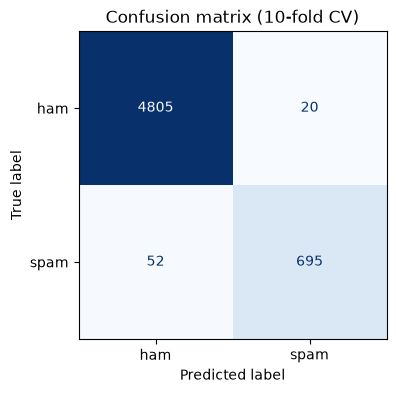

In [19]:
y_pred = cross_val_predict(pipe, X, y, cv=cv)

fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=["ham", "spam"], cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Confusion matrix (10-fold CV)")
plt.show()

## (d) Discussion

Yes, Naive Bayes is a good model for this problem. Using 10-fold stratified cross-validation, it gets about 98.7% accuracy, 97.3% precision, 93.0% recall, and 0.951 F1-score for spam, and the scores barely change across folds, so the result is stable. It is also very fast and simple, since training just counts how often each word appears in ham and spam messages. The data is imbalanced (about 87% ham), so always predicting "ham" would already get about 87% accuracy. That is why precision, recall, and F1 on the spam class are more useful than accuracy alone.